In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
# Carregar os dados do arquivo Excel
df = pd.read_excel('dados/Consumo e Produção Mundial.xlsx')

/usr/local/lib/python3.10/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


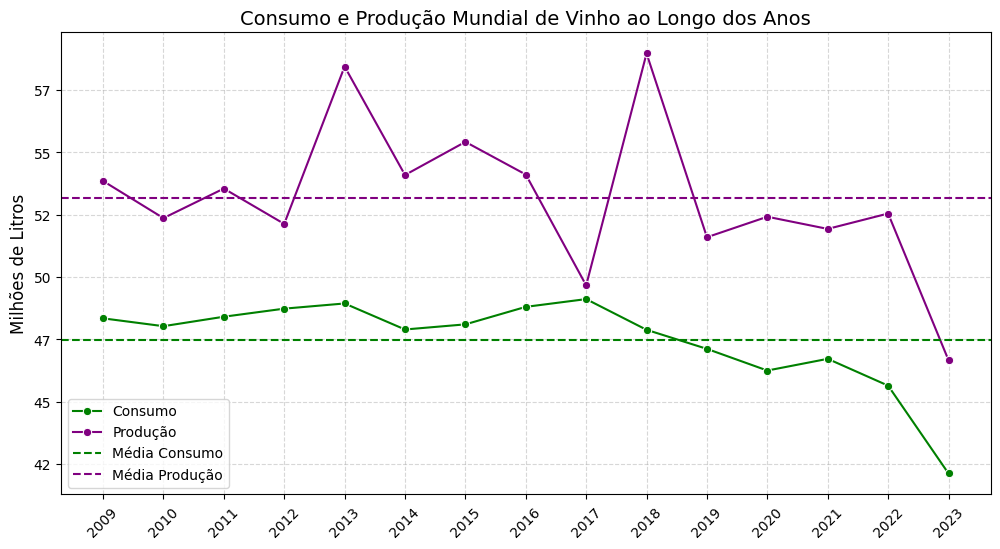

In [31]:
# Filtrar os dados para consumo e produção mundial (incluindo o Brasil)
df_consumo_mundial = df[df['Variable'] == 'Consumption']
df_producao_mundial = df[df['Variable'] == 'Production']

# Agrupar por ano e somar as quantidades para o consumo e a produção mundial
df_consumo_mundial_ano = df_consumo_mundial.groupby('Year')['Quantity'].sum().reset_index()
df_producao_mundial_ano = df_producao_mundial.groupby('Year')['Quantity'].sum().reset_index()

# Dividir a quantidade por 10
df_consumo_mundial_ano['Quantity'] /= 10000
df_producao_mundial_ano['Quantity'] /= 10000

# Calcular médias para o consumo e produção mundial
media_consumo_mundial = df_consumo_mundial_ano['Quantity'].mean()
media_producao_mundial = df_producao_mundial_ano['Quantity'].mean()

# Gráfico de Consumo e Produção mundial
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_consumo_mundial_ano, x='Year', y='Quantity', color='green', marker='o', label='Consumo')
sns.lineplot(data=df_producao_mundial_ano, x='Year', y='Quantity', color='purple', marker='o', label='Produção')

# Adicionar linhas pontilhadas para as médias
plt.axhline(media_consumo_mundial, color='green', linestyle='--', label='Média Consumo')
plt.axhline(media_producao_mundial, color='purple', linestyle='--', label='Média Produção')

# Personalizar o gráfico
plt.title('Consumo e Produção Mundial de Vinho ao Longo dos Anos', fontsize=14)
plt.ylabel('Milhões de Litros', fontsize=12)
plt.legend(loc='lower left', title=None)  # Legenda no canto inferior esquerdo
plt.grid(True, linestyle='--', alpha=0.5)

# Garantir que os anos estejam como inteiros e não contêm NaN
anos_mundial = df['Year'].dropna().astype(int).unique()

# Ajustar os ticks do eixo X para mostrar todos os anos
plt.xticks(anos_mundial, rotation=45)
plt.xlabel('')  # Remover label do eixo X

# Formatar o eixo Y com separação de milhar
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f'{int(x):,}'.replace(',', '.')))

# Exibir o gráfico
plt.show()


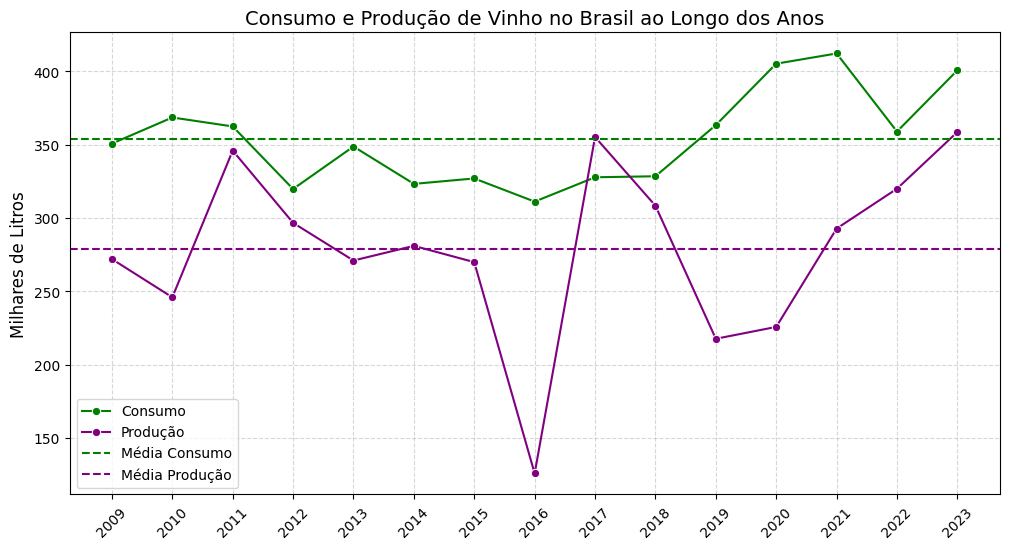

In [32]:
# Filtrar os dados para o Brasil
df_brasil = df[df['Region/Country'] == 'Brazil']

# Separar os dados de Consumo e Produção
df_consumo_brasil = df_brasil[df_brasil['Variable'] == 'Consumption']
df_producao_brasil = df_brasil[df_brasil['Variable'] == 'Production']

# Agrupar por ano e somar as quantidades (dividindo por 10)
df_consumo_brasil_ano = df_consumo_brasil.groupby('Year')['Quantity'].sum().reset_index()
df_producao_brasil_ano = df_producao_brasil.groupby('Year')['Quantity'].sum().reset_index()

# Dividir a quantidade por 10
df_consumo_brasil_ano['Quantity'] /= 10
df_producao_brasil_ano['Quantity'] /= 10

# Calcular médias
media_consumo_brasil = df_consumo_brasil_ano['Quantity'].mean()
media_producao_brasil = df_producao_brasil_ano['Quantity'].mean()

# Gráfico de Consumo e Produção do Brasil
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_consumo_brasil_ano, x='Year', y='Quantity', color='green', marker='o', label='Consumo')
sns.lineplot(data=df_producao_brasil_ano, x='Year', y='Quantity', color='purple', marker='o', label='Produção')

# Adicionar linhas pontilhadas para as médias
plt.axhline(media_consumo_brasil, color='green', linestyle='--', label='Média Consumo')
plt.axhline(media_producao_brasil, color='purple', linestyle='--', label='Média Produção')

# Personalizar o gráfico
plt.title('Consumo e Produção de Vinho no Brasil ao Longo dos Anos', fontsize=14)
plt.ylabel('Milhares de Litros', fontsize=12)
plt.legend(title=None)  # Remover título da legenda
plt.grid(True, linestyle='--', alpha=0.5)

# Garantir que os anos estejam como inteiros e não contêm NaN
anos_brasil = df_brasil['Year'].dropna().astype(int).unique()

# Ajustar os ticks do eixo X para mostrar todos os anos
plt.xticks(anos_brasil, rotation=45)
plt.xlabel('')  # Remover label do eixo X

# Exibir o gráfico
plt.show()


In [33]:
df_producao_brasil_ano['Quantity'].max()

358.7

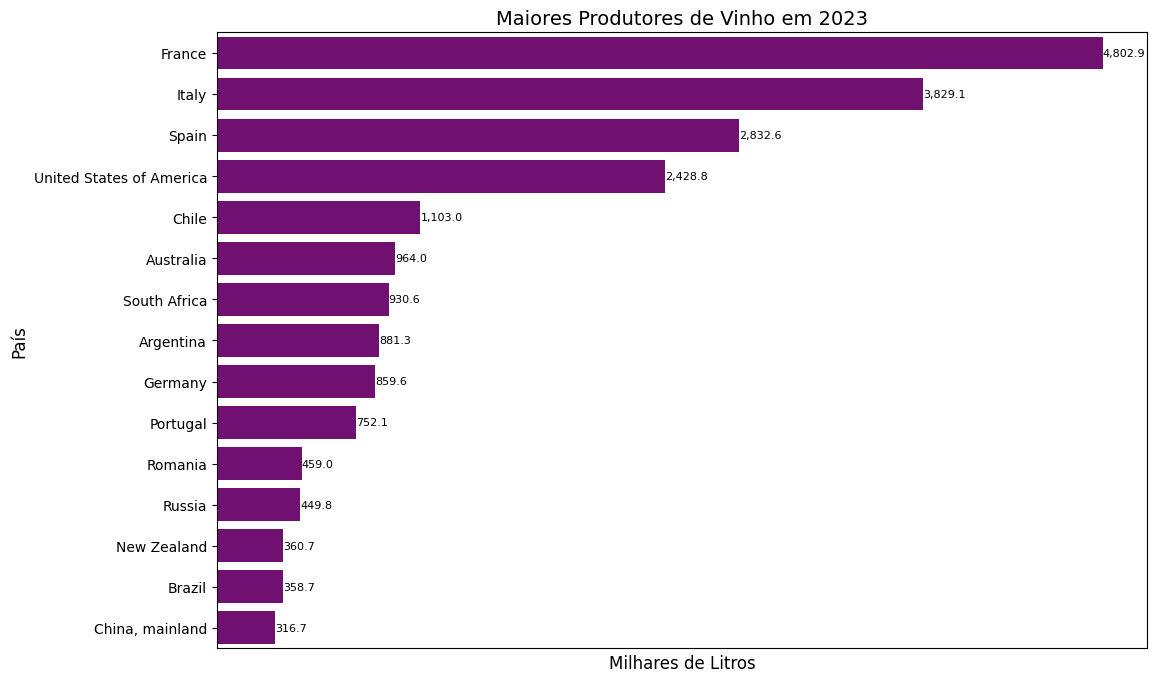

In [69]:
# Filtrar os dados para o ano de 2023 e para a produção de vinho
df_producao_2023 = df[(df['Year'] == 2023) & (df['Variable'] == 'Production')]

# Excluir a linha onde o país é "Global"
df_producao_2023 = df_producao_2023[df_producao_2023['Region/Country'] != 'Global']

# Agrupar por país e somar a quantidade de produção
df_producao_2023_agrupada = df_producao_2023.groupby('Region/Country')['Quantity'].sum().reset_index()

# Dividir a quantidade por 10 (para ajustar a unidade para milhares de litros)
df_producao_2023_agrupada['Quantity'] /= 10

# Ordenar os países pela quantidade de produção, do maior para o menor
df_producao_2023_agrupada_sorted = df_producao_2023_agrupada.sort_values(by='Quantity', ascending=False)

# Pegar os 15 países com maior produção (incluindo o Brasil)
df_top_15_2023 = df_producao_2023_agrupada_sorted.head(15)

# Gráfico de barras horizontais para a produção de vinho em 2023
plt.figure(figsize=(12, 8))

# Plotar a produção para todos os países como barras horizontais
sns.barplot(data=df_top_15_2023, x='Quantity', y='Region/Country', color='purple')

# Adicionar os valores à direita das barras
for i, v in enumerate(df_top_15_2023['Quantity']):
    # Ajustar o texto dependendo da posição para garantir que não saia da margem
    plt.text(v + 0.5, i, f'{v:,.1f}', va='center', fontsize=8, ha='left')

# Personalizar o gráfico
plt.title('Maiores Produtores de Vinho em 2023', fontsize=14)
plt.xlabel('Milhares de Litros', fontsize=12)
plt.ylabel('País', fontsize=12)

# Remover os valores do eixo X
plt.xticks([])

# Exibir o gráfico
plt.show()

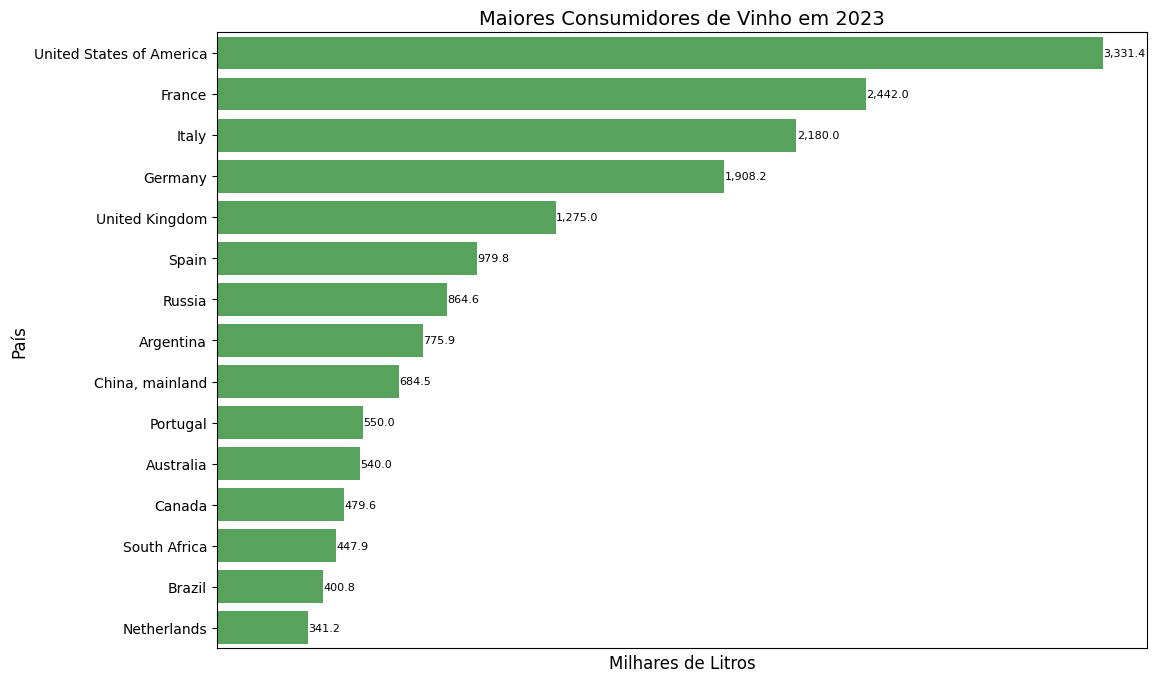

In [67]:
# Filtrar os dados para o ano de 2023 e para o consumo de vinho
df_consumo_2023 = df[(df['Year'] == 2023) & (df['Variable'] == 'Consumption')]

# Excluir a linha onde o país é "Global"
df_consumo_2023 = df_consumo_2023[df_consumo_2023['Region/Country'] != 'Global']

# Agrupar por país e somar a quantidade de consumo
df_consumo_2023_agrupada = df_consumo_2023.groupby('Region/Country')['Quantity'].sum().reset_index()

# Dividir a quantidade por 10 (para ajustar a unidade para milhares de litros)
df_consumo_2023_agrupada['Quantity'] /= 10

# Ordenar os países pela quantidade de consumo, do maior para o menor
df_top_15_consumo_2023 = df_consumo_2023_agrupada.sort_values(by='Quantity', ascending=False).head(15)

# Gráfico de barras horizontais para o consumo de vinho em 2023
plt.figure(figsize=(12, 8))

# Plotar o consumo para todos os países como barras horizontais com cor verde
sns.barplot(data=df_top_15_consumo_2023, x='Quantity', y='Region/Country', color='#4CAF50')  # Cor verde

# Adicionar os valores à direita das barras
for i, v in enumerate(df_top_15_consumo_2023['Quantity']):
    # Ajustar o texto dependendo da posição para garantir que não saia da margem
    plt.text(v + 0.5, i, f'{v:,.1f}', va='center', fontsize=8, ha='left')  # Fonte ajustada para 8

# Personalizar o gráfico
plt.title('Maiores Consumidores de Vinho em 2023', fontsize=14)
plt.xlabel('Milhares de Litros', fontsize=12)
plt.ylabel('País', fontsize=12)

# Remover os valores do eixo X
plt.xticks([])

# Exibir o gráfico
plt.show()

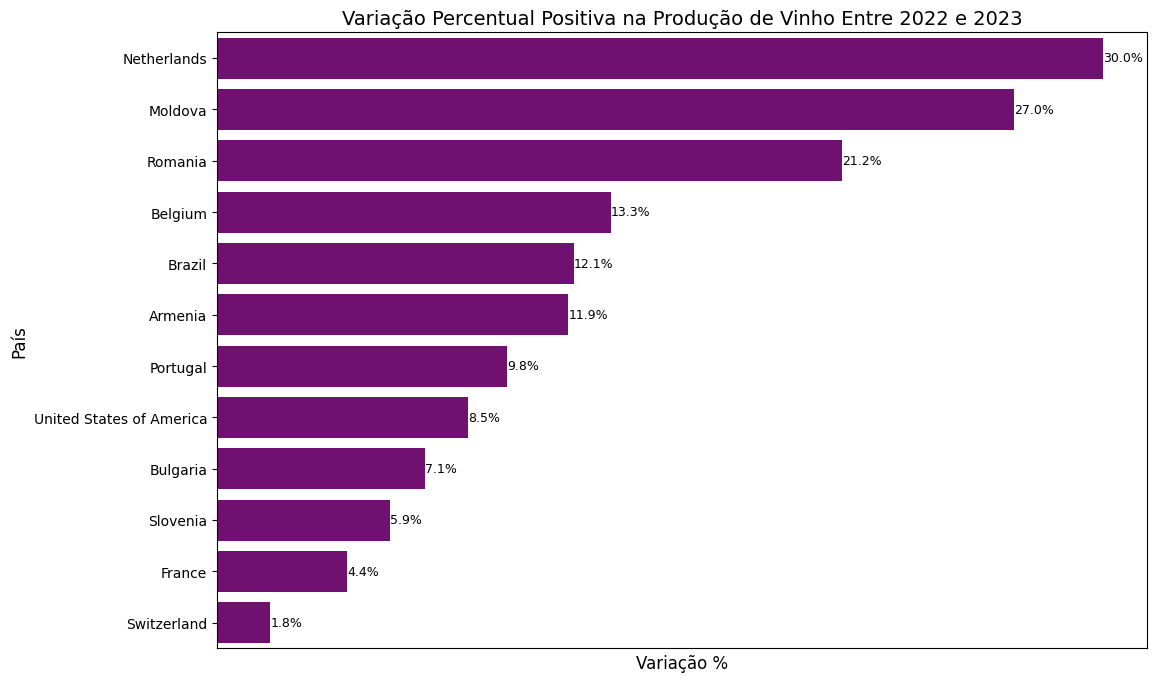

In [72]:
# Filtrar os dados de Produção para 2023 e 2022
df_producao_2023 = df[(df['Variable'] == 'Production') & (df['Year'] == 2023)]
df_producao_2022 = df[(df['Variable'] == 'Production') & (df['Year'] == 2022)]

# Mesclar os dois DataFrames para calcular a variação
df_comparacao_producao = pd.merge(df_producao_2023[['Region/Country', 'Quantity']],
                                   df_producao_2022[['Region/Country', 'Quantity']],
                                   on='Region/Country',
                                   suffixes=('_2023', '_2022'))

# Calcular a variação percentual entre 2023 e 2022
df_comparacao_producao['Variação %'] = ((df_comparacao_producao['Quantity_2023'] - df_comparacao_producao['Quantity_2022']) / df_comparacao_producao['Quantity_2022']) * 100

# Filtrar apenas variações positivas
df_comparacao_producao_positiva = df_comparacao_producao[df_comparacao_producao['Variação %'] > 0]

# Ordenar pela variação percentual em ordem decrescente
df_comparacao_producao_sorted = df_comparacao_producao_positiva.sort_values('Variação %', ascending=False)

# Gráfico de barras da variação percentual
plt.figure(figsize=(12, 8))
sns.barplot(data=df_comparacao_producao_sorted, x='Variação %', y='Region/Country', color='purple')  # Cor roxa

# Adicionar rótulos de valor na barra
for index, value in enumerate(df_comparacao_producao_sorted['Variação %']):
    plt.text(value, index, f'{value:.1f}%', va='center', ha='left', fontsize=9)

# Ajustar o título e os rótulos
plt.title('Variação Percentual Positiva na Produção de Vinho Entre 2022 e 2023', fontsize=14)
plt.xlabel('Variação %', fontsize=12)
plt.ylabel('País', fontsize=12)

# Remover os ticks do eixo X
plt.xticks([])

# Exibir o gráfico
plt.show()

In [56]:
# Filtrar os dados para 2023 e para produção
df_producao_2023 = df[(df['Variable'] == 'Production') & (df['Year'] == 2023)]

# Contar quantos países possuem valores de produção em 2023
num_paises_2023 = df_producao_2023['Region/Country'].nunique()

# Exibir o número de países
print(f'Número de países com dados de produção em 2023: {num_paises_2023}')

Número de países com dados de produção em 2023: 37


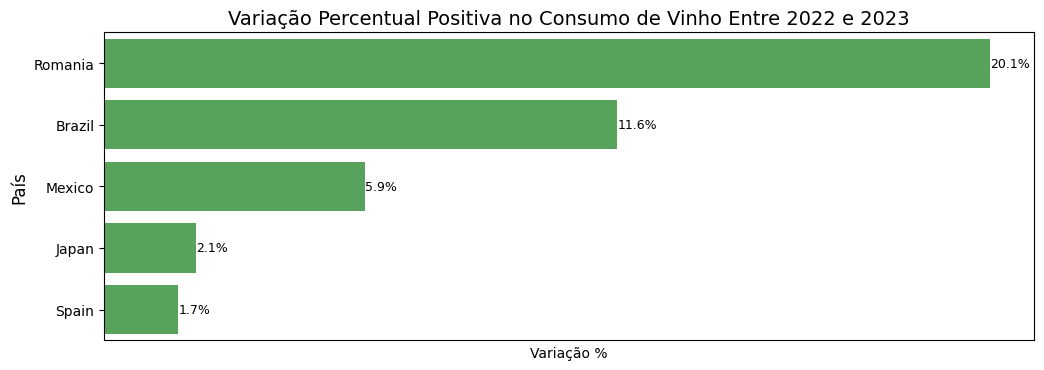

In [74]:
# Filtrar os dados de Consumo para 2023 e 2022
df_consumo_2023 = df[(df['Variable'] == 'Consumption') & (df['Year'] == 2023)]
df_consumo_2022 = df[(df['Variable'] == 'Consumption') & (df['Year'] == 2022)]

# Mesclar os dois DataFrames para calcular a variação
df_comparacao_consumo = pd.merge(df_consumo_2023[['Region/Country', 'Quantity']],
                                 df_consumo_2022[['Region/Country', 'Quantity']],
                                 on='Region/Country',
                                 suffixes=('_2023', '_2022'))

# Calcular a variação percentual entre 2023 e 2022
df_comparacao_consumo['Variação %'] = ((df_comparacao_consumo['Quantity_2023'] - df_comparacao_consumo['Quantity_2022']) / df_comparacao_consumo['Quantity_2022']) * 100

# Filtrar apenas variações positivas
df_comparacao_consumo_positiva = df_comparacao_consumo[df_comparacao_consumo['Variação %'] > 0]

# Ordenar pela variação percentual em ordem decrescente
df_comparacao_consumo_sorted = df_comparacao_consumo_positiva.sort_values('Variação %', ascending=False)

# Gráfico de barras da variação percentual
plt.figure(figsize=(12, 4))
sns.barplot(data=df_comparacao_consumo_sorted, x='Variação %', y='Region/Country', color='#4CAF50')  # Cor verde

# Adicionar rótulos de valor na barra
for index, value in enumerate(df_comparacao_consumo_sorted['Variação %']):
    plt.text(value, index, f'{value:.1f}%', va='center', ha='left', fontsize=9)

# Ajustar o título e os rótulos
plt.title('Variação Percentual Positiva no Consumo de Vinho Entre 2022 e 2023', fontsize=14)
plt.ylabel('País', fontsize=12)

# Remover os ticks do eixo X
plt.xticks([])

# Exibir o gráfico
plt.show()

In [59]:
# Filtrar os dados para 2023 e para consumo
df_consumo_2023 = df[(df['Variable'] == 'Consumption') & (df['Year'] == 2023)]

# Contar quantos países possuem valores de consumo em 2023
num_paises_2023_consumo = df_consumo_2023['Region/Country'].nunique()

# Exibir o número de países
print(f'Número de países com dados de consumo em 2023: {num_paises_2023_consumo}')

Número de países com dados de consumo em 2023: 32
